# SOFR Swap Spreads: Fair Value, Relative-Value Trading and Hedging with Machine Learning

A 30-year swap now yields less than a 30-year Treasury, something that would have looked impossible before 2008. Swap spreads today reflect the cost of holding Treasuries on bank balance sheets far more than credit risk. For a treasury desk that means a basis risk in every swap hedge, and a classic relative-value trade. This notebook builds the spreads from public trade reports, explains what drives them, and tests trading and hedging rules.

**What it does.** It builds two years of daily **SOFR swap rates** (2, 5, 10 and 30 years) from every interest-rate swap publicly reported to the DTCC repository, together with the **swap spreads** against Treasury yields. It then works in three steps:

1. **Fair value.** Ridge regression and LightGBM explain the spreads with their economic drivers: repo pressure, the Fed balance sheet and reverse repo, Treasury supply, the term premium and rate volatility. The residual is a rich/cheap signal.
2. **Relative value.** A DV01-neutral spread trade (swap against Treasury) is backtested walk-forward with costs. The signals are mean reversion, the fair-value residual and an ML forecast of the 20-day spread change.
3. **Hedging.** A Treasury position is hedged with swaps, using hedge ratios from DV01 matching, rolling OLS, a Kalman filter and a state-dependent LightGBM beta.

**Data.** The DTCC public swap data repository (CFTC cumulative rates reports, November 2024 to today), FRED (Treasury yields, SOFR, IORB, Fed balance sheet, reverse repo, TGA, Kim–Wright term premium, VIX), Treasury Fiscal Data (debt to the penny) and Yahoo Finance (MOVE index).

**Methods.** Robust aggregation of trades, ridge, LightGBM, SHAP, walk-forward backtests, a Kalman filter and conditional betas.

## 1. What a swap spread is and why it moves

The **swap spread** at maturity *n* is the fixed rate of an *n*-year SOFR swap minus the yield of the *n*-year Treasury. Before 2008 it was positive: banks' credit risk was in LIBOR. Since then long swap spreads have been **negative**: a 30-year swap yields less than a 30-year Treasury. Swap spreads reflect the **balance-sheet cost of holding Treasuries**, not credit:
- **Supply:** heavy Treasury issuance cheapens bonds against swaps, so spreads fall.
- **Dealer balance sheets:** the supplementary leverage ratio (SLR) makes it costly for banks to warehouse Treasuries, so more negative spreads persist.
- **Repo / funding:** a long-Treasury, pay-fixed position (the "spread trade") is funded in repo. When SOFR trades above the Fed's interest on reserves, carrying bonds costs more.
- **Volatility and hedging flows:** mortgage convexity hedging, pension liability-driven investment (receiving long swaps) and corporate issuance swaps.

For a treasury desk the spread is a **basis risk**. Hedging a bond portfolio with swaps, or valuing a swap book against a bond benchmark, leaves exposure to spread moves. It is also a classic **relative-value trade**.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import zipfile
import lightgbm as lgb
import shap
import yfinance as yf
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 47
rng = np.random.default_rng(SEED)
DTCC_URL = "https://kgc0418-tdw-data-0.s3.amazonaws.com/cftc/eod/CFTC_CUMULATIVE_RATES_{d:%Y_%m_%d}.zip"
# first public cumulative report kept on the repository
DTCC_START = dt.date(2024, 11, 1)
TENORS = {24: "2y", 60: "5y", 120: "10y", 360: "30y"}
UST = {"2y": "DGS2", "5y": "DGS5", "10y": "DGS10", "30y": "DGS30"}
# trading days ahead for the RV forecast
HORIZON = 20
# round-trip cost of the spread trade, bp of spread (assumption)
COST_BP = 0.5

print(
    f"lightgbm {lgb.__version__} · shap {shap.__version__} · yfinance"
    f" {yf.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · shap 0.54.1 · yfinance 1.7.0 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Daily SOFR swap rates from reported trades

Every business-day cumulative report since November 2024 is read, keeping USD SOFR overnight-index swaps.

**Filters:**
- new trades only (`NEWT`), with no package or non-standard terms;
- spot-starting (effective within seven days of execution);
- tenor within ±2% of 2, 5, 10 or 30 years;
- fixed rates that are exact multiples of 12.5 bp are dropped: these are standard-coupon (MAC) swaps that trade with an upfront fee;
- only trades executed between **1 pm and 4 pm New York time** are kept. The Treasury constant-maturity yields are marked around the 3:30 pm close, so matching the time window removes most of the intraday noise from the spread. Using all trades of the day roughly halves the explained share of daily Treasury moves.

**The daily rate** is the notional-weighted median of the trades after removing outliers beyond three median absolute deviations. Days with fewer than three trades at a tenor in the window are left empty and forward-filled at most two days.

In [3]:
def fetch_day(day):
    r = requests.get(DTCC_URL.format(d=day), timeout=120)
    if r.status_code != 200:
        return None
    z = zipfile.ZipFile(io.BytesIO(r.content))
    raw = pd.read_csv(z.open(z.namelist()[0]), dtype=str, low_memory=False)
    m = raw["UPI FISN"].fillna("").eq("NA/Swap OIS USD") & raw[
        "UPI Underlier Name"
    ].fillna("").str.contains("SOFR")
    keep = [
        "Action type",
        "Execution Timestamp",
        "Effective Date",
        "Expiration Date",
        "Package indicator",
        "Non-standardized term indicator",
        "Notional amount-Leg 1",
        "Fixed rate-Leg 1",
        "Fixed rate-Leg 2",
    ]
    x = raw.loc[m, [c for c in keep if c in raw.columns]].copy()
    x["file_date"] = day.isoformat()
    return x


def fetch_history():
    out, day = [], DTCC_START
    while day < dt.date.today():
        if day.weekday() < 5:
            try:
                x = fetch_day(day)
                if x is not None:
                    out.append(x)
            except requests.RequestException:
                pass
        day += dt.timedelta(days=1)
    return pd.concat(out, ignore_index=True)


raw = cached("dtcc_sofr_ois_history", fetch_history, max_age_hours=24 * 7)
t = raw.copy()
t["ts"] = pd.to_datetime(t["Execution Timestamp"], errors="coerce", utc=True)
t["trade"] = t["ts"].dt.tz_convert(None).dt.normalize()
ny = t["ts"].dt.tz_convert("America/New_York")
t["ny_hour"] = ny.dt.hour + ny.dt.minute / 60
t["eff"], t["exp"] = pd.to_datetime(
    t["Effective Date"], errors="coerce"
), pd.to_datetime(t["Expiration Date"], errors="coerce")
t["rate"] = pd.to_numeric(t["Fixed rate-Leg 1"], errors="coerce").fillna(
    pd.to_numeric(t["Fixed rate-Leg 2"], errors="coerce")
)
t["notional"] = (
    pd.to_numeric(
        t["Notional amount-Leg 1"].str.replace(r"[^0-9.]", "", regex=True),
        errors="coerce",
    )
    .fillna(1e6)
    .clip(1e5, 1e10)
)
t["len_m"] = (t["exp"] - t["eff"]).dt.days / 30.4375
mac = np.abs(t["rate"] * 800 - np.round(t["rate"] * 800)) < 1e-6
t = t[
    (t["Action type"] == "NEWT")
    & (t["Package indicator"] != "TRUE")
    & (t["Non-standardized term indicator"] != "TRUE")
    & ~mac
    & ((t["eff"] - t["trade"]).dt.days.between(0, 7))
    & t["rate"].between(0, 0.1)
    & (t["trade"].dt.date.astype(str) == t["file_date"])
    # 1–4 pm New York, around the Treasury close marks
    & t["ny_hour"].between(13, 16)
]
rows = []
for m_, lab in TENORS.items():
    s_ = t[np.abs(t["len_m"] / m_ - 1) < 0.02]
    for d_, g in s_.groupby("file_date"):
        if len(g) < 3:
            continue
        med = g["rate"].median()
        mad = (g["rate"] - med).abs().median()
        g = g[(g["rate"] - med).abs() <= max(3 * 1.4826 * mad, 1e-4)]
        o = np.argsort(g["rate"].to_numpy())
        w = g["notional"].to_numpy()[o].cumsum()
        rows.append({
            "date": d_,
            "tenor": lab,
            "rate": (
                g["rate"].to_numpy()[o][np.searchsorted(w, w[-1] / 2)] * 100
            ),
            "trades": len(g),
        })
sw = pd.DataFrame(rows).pivot(index="date", columns="tenor", values="rate")[
    list(TENORS.values())
]
sw.index = pd.to_datetime(sw.index)
sw = sw.ffill(limit=2)
ntr = pd.DataFrame(rows).groupby("tenor")["trades"].median()
print(
    f"{len(t):,} clean spot SOFR OIS trades · {len(sw)} days"
    f" {sw.index.min():%Y-%m-%d} → {sw.index.max():%Y-%m-%d} · median trades"
    " per day: "
    + ", ".join(
        f"{k} {int(v)}" for k, v in ntr.reindex(list(TENORS.values())).items()
    )
)
sw.describe().round(3)

126,246 clean spot SOFR OIS trades · 488 days 2024-11-01 → 2026-10-19 · median trades per day: 2y 15, 5y 31, 10y 41, 30y 24


tenor,2y,5y,10y,30y
count,488.00,488.00,488.00,488.00
mean,3.75,3.74,3.93,4.09
std,0.37,0.35,0.28,0.27
min,3.19,3.21,3.49,3.54
25%,3.42,3.46,3.75,3.94
50%,3.72,3.67,3.86,4.06
75%,4.04,3.98,4.07,4.19
max,4.76,4.81,4.95,5.03


## 4. Swap spreads and their drivers

**Treasury yields** are the constant-maturity par yields from FRED. The spread is quoted the market way: swap rate (annual, ACT/360) minus Treasury yield (semi-annual), in basis points.

**Drivers, daily, aligned on the swap dates:**

| driver | series | why |
|---|---|---|
| repo pressure | SOFR − IORB | funding cost of carrying Treasuries |
| Fed securities | Fed total assets (WALCL), 13-week change | QT removes a buyer |
| reverse repo | ON RRP balance | excess liquidity cushion |
| Treasury cash | TGA balance | liquidity drained by Treasury |
| supply | total public debt outstanding, 3-month change | issuance pressure |
| term premium | Kim–Wright 10y term premium | duration supply/demand |
| volatility | MOVE, VIX | hedging and risk appetite |
| level and slope | 10y yield, 10y − 2y | convexity hedging and curve flows |

In [4]:
fr = {
    k: fred.get_series(v)
    for k, v in {
        **UST,
        "sofr": "SOFR",
        "iorb": "IORB",
        "walcl": "WALCL",
        "rrp": "RRPONTSYD",
        "tga": "WTREGEN",
        "tp10": "THREEFYTP10",
        "vix": "VIXCLS",
    }.items()
}
F = pd.DataFrame(fr).sort_index().ffill()
debt = pd.DataFrame(
    requests.get(
        "https://api.fiscaldata.treasury.gov/services/api/fiscal_service/v2/accounting/od/debt_to_penny",
        params={
            "fields": "record_date,tot_pub_debt_out_amt",
            "filter": "record_date:gte:2023-06-01",
            "page[size]": 10000,
        },
        timeout=60,
    ).json()["data"]
)
debt = pd.Series(
    pd.to_numeric(debt["tot_pub_debt_out_amt"]).to_numpy() / 1e12,
    index=pd.to_datetime(debt["record_date"]),
).sort_index()
move = cached(
    "move_index",
    lambda: yf.download(
        "^MOVE", start="2023-06-01", progress=False, auto_adjust=False
    )["Close"]
    .squeeze()
    .rename("move")
    .to_frame(),
    max_age_hours=24,
)["move"]
D = F.reindex(sw.index, method="ffill")
spread = pd.DataFrame({k: (sw[k] - D[k]) * 100 for k in UST}, index=sw.index)
X = pd.DataFrame(index=sw.index)
X["repo_gap_bp"] = (D["sofr"] - D["iorb"]) * 100
X["fed_assets_13w_chg"] = (
    (F["walcl"] / 1e6).diff(91).reindex(sw.index, method="ffill")
)
X["rrp_bn"] = D["rrp"]
X["tga_bn"] = D["tga"] / 1e3
X["debt_3m_chg_tn"] = debt.diff(63).reindex(sw.index, method="ffill")
X["term_premium"] = D["tp10"]
X["move"] = move.reindex(sw.index, method="ffill")
X["vix"] = D["vix"]
X["level_10y"] = D["10y"]
X["slope_2s10s"] = (D["10y"] - D["2y"]) * 100
X = X.ffill().dropna()
spread = spread.loc[X.index].dropna()
X = X.loc[spread.index]
print(
    f"{len(spread)} days with spreads and drivers · latest"
    f" ({spread.index[-1]:%Y-%m-%d}): "
    + ", ".join(f"{k} {v:+.1f} bp" for k, v in spread.iloc[-1].items())
)
spread.describe().round(1)

488 days with spreads and drivers · latest (2026-10-19): 2y -14.5 bp, 5y -28.5 bp, 10y -39.8 bp, 30y -63.6 bp


,2y,5y,10y,30y
count,488.00,488.00,488.00,488.00
mean,-18.20,-31.50,-45.90,-77.20
std,4.70,4.10,5.80,6.90
min,-56.10,-45.20,-58.80,-95.00
25%,-21.70,-35.20,-51.10,-83.00
50%,-17.30,-30.50,-45.10,-76.50
75%,-14.90,-28.20,-41.30,-72.20
max,-7.70,-22.70,-35.00,-61.50


## 5. Fair value: what explains the level of the spreads

For each tenor, the spread level is regressed on the drivers with:
- **ridge regression**: standardised drivers, penalty chosen by cross-validation;
- **LightGBM**: shallow trees.

Validation is by **blocked time folds**: five contiguous blocks, each predicted by a model trained on the other four plus a 10-day embargo. This avoids the leakage a random split would create on autocorrelated daily data.

The out-of-fold residual (actual minus fair value) is the **rich/cheap signal**:
- positive means the swap rate is high against bonds, so the spread is "too wide";
- negative means it is too tight.

In [5]:
def blocked_oof(model_fn, Xm, y, k=5, embargo=10):
    n, pred = len(y), np.full(len(y), np.nan)
    edges = np.linspace(0, n, k + 1).astype(int)
    for a, b in zip(edges[:-1], edges[1:]):
        tr = np.r_[0 : max(a - embargo, 0), min(b + embargo, n) : n]
        pred[a:b] = (
            model_fn().fit(Xm.iloc[tr], y.iloc[tr]).predict(Xm.iloc[a:b])
        )
    return pred


ridge_fn = lambda: make_pipeline(
    StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))
)
gbm_fn = lambda: lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=7,
    min_child_samples=20,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    verbose=-1,
    random_state=SEED,
)
fv_rows, RESID, FV = [], {}, {}
for k in UST:
    y = spread[k]
    pr, pg = blocked_oof(ridge_fn, X, y), blocked_oof(gbm_fn, X, y)
    FV[k], RESID[k] = pg, y - pg
    r2 = lambda p_: 1 - np.mean((y - p_) ** 2) / np.var(y)
    fv_rows.append({
        "tenor": k,
        "spread s.d. (bp)": y.std(),
        "R² ridge": r2(pr),
        "R² LightGBM": r2(pg),
        "RMSE LightGBM (bp)": np.sqrt(np.mean((y - pg) ** 2)),
        "residual half-life (days)": np.log(2) / -np.log(
            max(min(pd.Series(y - pg).autocorr(1), 0.999), 0.01)
        ),
    })
FVT = pd.DataFrame(fv_rows).set_index("tenor")
gb10 = gbm_fn().fit(X, spread["10y"])
sv = shap.TreeExplainer(gb10).shap_values(X)
shap10 = pd.Series(np.abs(sv).mean(0), index=X.columns).sort_values(
    ascending=False
)
rd10 = ridge_fn().fit(X, spread["10y"])
coef10 = pd.Series(rd10[-1].coef_, index=X.columns).rename(
    "ridge coefficient (bp per s.d.)"
)
display(FVT.round(2))
pd.concat(
    [shap10.rename("mean |SHAP| (bp), 10y LightGBM"), coef10], axis=1
).round(2)

,spread s.d. (bp),R² ridge,R² LightGBM,RMSE LightGBM (bp),residual half-life (days)
tenor,,,,,
2y,4.67,0.04,-0.28,5.28,1.71
5y,4.10,-0.02,-0.18,4.44,8.04
10y,5.76,0.08,-0.13,6.12,11.54
30y,6.94,-0.27,0.11,6.54,5.63


,"mean |SHAP| (bp), 10y LightGBM",ridge coefficient (bp per s.d.)
tga_bn,1.92,0.48
rrp_bn,1.25,-1.84
fed_assets_13w_chg,1.16,-2.92
slope_2s10s,1.05,-0.65
debt_3m_chg_tn,0.62,-2.18
vix,0.48,-0.90
level_10y,0.30,-8.45
move,0.23,-0.40
term_premium,0.20,11.02
repo_gap_bp,0.12,1.58


## 6. Relative value: trading the 10-year swap spread

**The trade.** Long the spread means receive the Treasury yield and pay the swap rate, DV01-neutral: buy the bond, pay fixed in the swap. It earns when the spread widens. Profit and loss is measured in basis points of spread per unit DV01; carry and funding are ignored. Positions are held for 20 trading days, rebalanced daily as overlapping sleeves, and charged 0.5 bp per round trip.

**Signals**, all walk-forward: each day uses only models fitted on data up to 20 days before.
1. **Mean reversion:** −(spread − 60-day mean) / 60-day s.d.
2. **Fair-value residual:** −residual / its 60-day s.d., from a LightGBM fair-value model refitted every 20 days on past data only.
3. **ML forecast:** LightGBM predicting the next 20-day spread change from the drivers, their 20-day changes and the spread's own z-score and momentum.

A naive **always long** and **always short** pair shows the drift of the sample.

In [6]:
y10 = spread["10y"]
fwd = y10.shift(-HORIZON) - y10
feat = pd.concat(
    [
        X,
        X.diff(HORIZON).add_suffix("_chg20"),
        ((y10 - y10.rolling(60).mean()) / y10.rolling(60).std()).rename("z60"),
        (y10 - y10.shift(HORIZON)).rename("mom20"),
    ],
    axis=1,
)
sig = pd.DataFrame(index=y10.index)
sig["mean reversion"] = -feat["z60"]
sig["fair-value residual"] = np.nan
sig["ML forecast"] = np.nan
MIN_TRAIN = 160
for i in range(MIN_TRAIN, len(y10), HORIZON):
    # labels known by day i
    past = slice(0, i - HORIZON)
    ok = feat.iloc[past].notna().all(axis=1) & fwd.iloc[past].notna()
    fv = gbm_fn().fit(X.iloc[:i], y10.iloc[:i])
    res_all = y10.iloc[: i + HORIZON] - fv.predict(X.iloc[: i + HORIZON])
    rs = res_all.rolling(60).std()
    sig.iloc[i : i + HORIZON, 1] = (
        (-res_all / rs).iloc[i : i + HORIZON].to_numpy()
    )
    if ok.sum() > 80:
        m = gbm_fn().fit(feat.iloc[past][ok], fwd.iloc[past][ok])
        blk = feat.iloc[i : i + HORIZON]
        sig.iloc[i : i + HORIZON, 2] = np.where(
            blk.notna().all(axis=1), m.predict(blk.fillna(0)), np.nan
        )
daily = y10.diff().shift(-1)  # next day's spread change


def backtest(s):
    # overlapping 20-day sleeves
    pos = np.sign(s).rolling(HORIZON, min_periods=1).mean()
    pnl = pos * daily - COST_BP / HORIZON * pos.diff().abs().fillna(0)
    return pnl.dropna()


start = y10.index[MIN_TRAIN]
bt = {k: backtest(sig[k].loc[start:]) for k in sig}
bt["always long"] = backtest(pd.Series(1.0, index=y10.loc[start:].index))
bt["always short"] = backtest(pd.Series(-1.0, index=y10.loc[start:].index))
perf = pd.DataFrame({
    k: {
        "total (bp)": v.sum(),
        "annualised Sharpe": (
            v.mean() / v.std() * np.sqrt(252) if v.std() > 0 else np.nan
        ),
        "hit rate (20d)": (
            np.mean(
                np.sign(sig[k].loc[start:]).iloc[:-HORIZON]
                == np.sign(fwd.loc[start:].iloc[:-HORIZON])
            )
            if k in sig
            else np.nan
        ),
        "IC (signal vs 20d change)": (
            sig[k].loc[start:].corr(fwd.loc[start:], method="spearman")
            if k in sig
            else np.nan
        ),
        "max drawdown (bp)": (v.cumsum() - v.cumsum().cummax()).min(),
    }
    for k, v in bt.items()
}).T
print(
    f"Backtest {start:%Y-%m-%d} →"
    f" {y10.index[-1]:%Y-%m-%d} ({len(bt['always long'])} days), cost"
    f" {COST_BP} bp per round trip"
)
perf.round(2)

Backtest 2025-06-26 → 2026-10-19 (327 days), cost 0.5 bp per round trip


,total (bp),annualised Sharpe,hit rate (20d),IC (signal vs 20d change),max drawdown (bp)
mean reversion,-0.30,-0.01,0.54,0.06,-17.50
fair-value residual,-2.62,-0.12,0.49,0.02,-14.90
ML forecast,-1.55,-0.08,0.50,-0.06,-13.50
always long,16.32,0.60,NaN,NaN,-14.20
always short,-16.32,-0.60,NaN,NaN,-22.64


## 7. Hedging a Treasury position with swaps

A $100 million position in the 10-year Treasury is hedged by paying fixed on a 10-year SOFR swap. Notionals are expressed as DV01 (dollar value of one basis point). The hedge ratio *h* is the swap DV01 per unit of bond DV01. Four rules:
1. **DV01 match:** h = 1, the textbook hedge;
2. **rolling OLS:** h = β of daily Treasury-yield changes on swap-rate changes over the last 60 days;
3. **Kalman filter:** β follows a random walk and is updated each day (state noise chosen on the first half of the sample);
4. **ML conditional beta:** LightGBM predicts the Treasury-yield change from the swap-rate change *and* the state (volatility, repo gap, curve slope, spread z-score), trained walk-forward. The hedge ratio is the model's local sensitivity to a ±1 bp swap move.

Effectiveness is the **variance reduction** of daily P&L against the unhedged position, out of sample.

In [7]:
du, ds_ = (
    D.loc[X.index, "10y"].diff() * 100,
    sw.loc[X.index, "10y"].diff() * 100,
)
H = (
    pd.DataFrame({"du": du, "ds": ds_})
    .join(X[["move", "repo_gap_bp", "slope_2s10s"]])
    .join(feat["z60"])
    .dropna()
)
roll = H["du"].rolling(60).cov(H["ds"]) / H["ds"].rolling(60).var()
beta = pd.DataFrame(index=H.index)
beta["DV01 match"] = 1.0
beta["rolling OLS (60d)"] = roll.shift(1)


def kalman(y_, x_, q):
    b, P, r, out = 1.0, 1.0, np.var(y_ - x_), []
    for yi, xi in zip(y_, x_):
        out.append(b)
        P += q
        k_ = P * xi / (xi * xi * P + r)
        b += k_ * (yi - b * xi)
        P *= 1 - k_ * xi
    return np.array(out)


half = len(H) // 2
qs = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]
best_q = min(
    qs,
    key=lambda q: np.var(
        H["du"].iloc[:half]
        - kalman(
            H["du"].iloc[:half].to_numpy(), H["ds"].iloc[:half].to_numpy(), q
        )
        * H["ds"].iloc[:half]
    ),
)
beta["Kalman"] = kalman(H["du"].to_numpy(), H["ds"].to_numpy(), best_q)
ml_beta = np.full(len(H), np.nan)
state = ["ds", "move", "repo_gap_bp", "slope_2s10s", "z60"]
for i in range(MIN_TRAIN, len(H), HORIZON):
    m = lgb.LGBMRegressor(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=7,
        min_child_samples=30,
        verbose=-1,
        random_state=SEED,
        monotone_constraints=[1, 0, 0, 0, 0],
    ).fit(H[state].iloc[:i], H["du"].iloc[:i])
    blk = H[state].iloc[i : i + HORIZON]
    ml_beta[i : i + HORIZON] = (
        m.predict(blk.assign(ds=1.0)) - m.predict(blk.assign(ds=-1.0))
    ) / 2
beta["ML conditional beta"] = ml_beta
oos = H.index[MIN_TRAIN:]
hedge = pd.DataFrame({
    k: {
        "mean hedge ratio": beta.loc[oos, k].mean(),
        "variance reduction (%)": 100 * (
            1
            - np.var(H.loc[oos, "du"] - beta.loc[oos, k] * H.loc[oos, "ds"])
            / np.var(H.loc[oos, "du"])
        ),
        "residual P&L s.d. ($k/day, $100mm 10y)": (
            np.std(H.loc[oos, "du"] - beta.loc[oos, k] * H.loc[oos, "ds"])
            * 0.0887
            * 1e3
        ),
    }
    for k in beta
}).T
print(
    f"Out-of-sample hedge test: {len(oos)} days from {oos[0]:%Y-%m-%d}; Kalman"
    f" state noise q = {best_q:g}; 10y DV01 ≈ $88.7k per $100mm"
)
hedge.round(3)

Out-of-sample hedge test: 269 days from 2025-09-19; Kalman state noise q = 0.0001; 10y DV01 ≈ $88.7k per $100mm


,mean hedge ratio,variance reduction (%),"residual P&L s.d. ($k/day, $100mm 10y)"
DV01 match,1.00,89.08,123.11
rolling OLS (60d),1.06,89.15,122.70
Kalman,1.05,89.27,122.02
ML conditional beta,1.25,82.47,155.95


## 8. Charts and dashboard

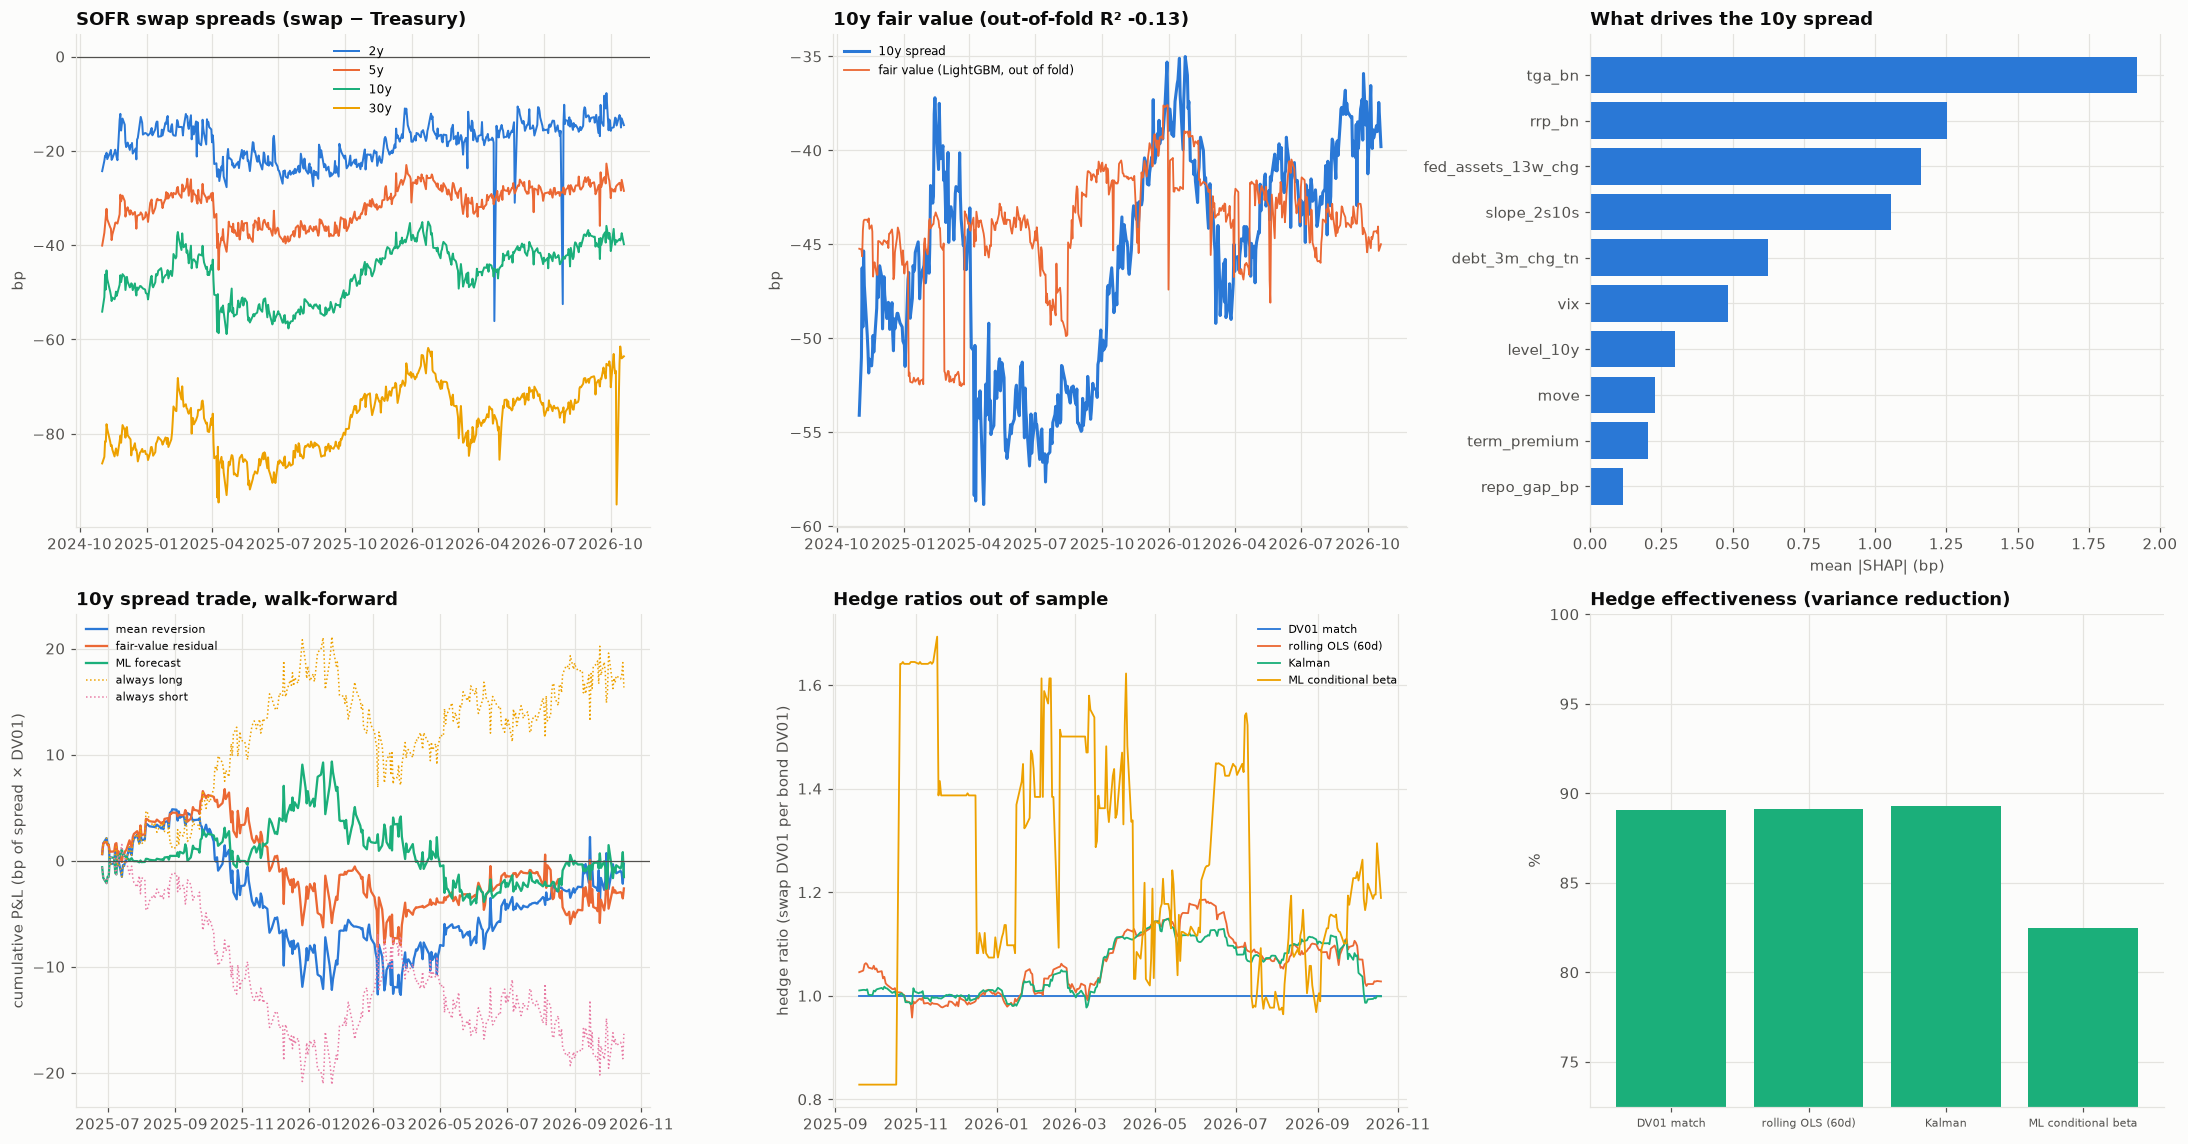

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10.5))
ax = axes[0, 0]
for k, c in zip(UST, PALETTE):
    ax.plot(spread.index, spread[k], color=c, lw=1.3, label=k)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_ylabel("bp")
ax.legend(fontsize=8)
ax.set_title("SOFR swap spreads (swap − Treasury)")
ax = axes[0, 1]
ax.plot(spread.index, spread["10y"], color=PALETTE[0], label="10y spread")
ax.plot(
    spread.index,
    FV["10y"],
    color=PALETTE[1],
    lw=1.2,
    label="fair value (LightGBM, out of fold)",
)
ax.set_ylabel("bp")
ax.legend(fontsize=8)
ax.set_title(
    f"10y fair value (out-of-fold R² {FVT.loc['10y', 'R² LightGBM']:.2f})"
)
ax = axes[0, 2]
ax.barh(shap10.index[::-1], shap10.values[::-1], color=PALETTE[0])
ax.set_xlabel("mean |SHAP| (bp)")
ax.set_title("What drives the 10y spread")
ax = axes[1, 0]
for (k, v), c in zip(bt.items(), PALETTE):
    ax.plot(
        v.index,
        v.cumsum(),
        color=c,
        lw=1.5 if k in sig else 1.0,
        ls="-" if k in sig else ":",
        label=k,
    )
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_ylabel("cumulative P&L (bp of spread × DV01)")
ax.legend(fontsize=7)
ax.set_title("10y spread trade, walk-forward")
ax = axes[1, 1]
for k, c in zip(beta.columns, PALETTE):
    ax.plot(beta.loc[oos].index, beta.loc[oos, k], color=c, lw=1.2, label=k)
ax.set_ylabel("hedge ratio (swap DV01 per bond DV01)")
ax.legend(fontsize=7)
ax.set_title("Hedge ratios out of sample")
ax = axes[1, 2]
ax.bar(hedge.index, hedge["variance reduction (%)"], color=PALETTE[2])
ax.set_ylim(max(0, hedge["variance reduction (%)"].min() - 10), 100)
ax.set_ylabel("%")
ax.tick_params(axis="x", labelsize=7)
ax.set_title("Hedge effectiveness (variance reduction)")
plt.tight_layout()
save_fig(fig, "01_swap_spreads")
plt.show()

In [9]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Swap spreads (bp)",
        "10y spread vs fair value",
        "Rich/cheap residual z-score (10y)",
        "Cumulative P&L of the RV signals",
    ),
)
for k, c in zip(UST, PALETTE):
    dash.add_trace(
        go.Scatter(x=spread.index, y=spread[k], name=k, line=dict(color=c)),
        1,
        1,
    )
dash.add_trace(
    go.Scatter(
        x=spread.index,
        y=spread["10y"],
        name="10y",
        line=dict(color=PALETTE[0]),
        showlegend=False,
    ),
    1,
    2,
)
dash.add_trace(
    go.Scatter(
        x=spread.index,
        y=FV["10y"],
        name="fair value",
        line=dict(color=PALETTE[1]),
    ),
    1,
    2,
)
dash.add_trace(
    go.Scatter(
        x=sig.index,
        y=-sig["fair-value residual"],
        name="residual z",
        line=dict(color=PALETTE[3]),
    ),
    2,
    1,
)
for (k, v), c in zip(bt.items(), PALETTE):
    dash.add_trace(
        go.Scatter(x=v.index, y=v.cumsum(), name=k, line=dict(color=c)), 2, 2
    )
dash.update_layout(
    height=820,
    width=1300,
    template="simple_white",
    title="SOFR swap spreads: fair value, signals and P&L",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

**The data.**
- About 126,000 clean spot-starting SOFR swaps, executed between 1 and 4 pm New York time, give daily 2/5/10/30-year swap rates for 488 days, November 2024 to October 2026. The median day has 15–41 trades per tenor.
- Matching the time window to the Treasury marks matters. With all-day trades a 10Y swap hedge explains only about 60% of daily Treasury moves; with the window it explains 89%.

**Two years of swap spreads.**
- All spreads are negative and steeply inverted in maturity: on the latest day −15 (2Y), −29 (5Y), −40 (10Y) and −64 bp (30Y).
- The sample has one violent episode. In **April 2025**, during the tariff sell-off, spreads collapsed: 10Y to −59 and 30Y to −95 bp, as leveraged basis and swap-spread positions were unwound and Treasuries cheapened sharply.
- Since then spreads have **widened back** by 10–25 bp, most at the long end. The usual explanations are the expected easing of the supplementary leverage ratio for banks and the end of QT, which let dealers carry more Treasuries.

**Fair value: an honest negative.**
- In sample, the drivers line up as theory says. SHAP ranks liquidity first (Treasury General Account, reverse repo, the Fed's balance-sheet change), then the curve slope and debt issuance.
- But with blocked, embargoed cross-validation **no model explains the spread level out of sample**: 10Y R² −0.13 for LightGBM and 0.08 for ridge.
- Two years contain essentially one regime shift (the April 2025 dislocation and its unwind). Relationships between slow liquidity variables and the spread are not stable enough to extrapolate.

**Relative value.**
- None of the three signals earned money after costs in the walk-forward test (June 2025 – October 2026):
  - mean reversion −0.3 bp, IC 0.06;
  - the fair-value residual −2.6 bp;
  - the ML forecast −1.5 bp, IC −0.06.
- Simply being **long the spread** (long Treasury, pay fixed) made +16 bp with a Sharpe of 0.6, because the sample is dominated by the post-April recovery.
- The residual half-life of 5–12 days shows mean reversion exists at very short horizons. It is too small and noisy for a 20-day trade with costs.

**Hedging.**
- Hedging a 10Y Treasury position with a 10Y SOFR swap removes **89% of daily P&L variance**, and the hedge-ratio method barely matters: DV01 match 89.1%, rolling OLS 89.1%, Kalman 89.3%.
- The **ML conditional beta is worse (82.5%)**. It learns unstable state-dependent ratios (up to 1.6) that do not hold out of sample.
- The residual basis risk is about $120k a day per $100mm of 10Y bonds, the cost of hedging bonds with swaps.

**Limitations.**
- Trade-based daily rates are noisier than dealer closing quotes.
- Constant-maturity Treasury yields are on-the-run par yields, while the swap is a fresh par swap; on-the-run premia and the coupon effect are ignored.
- Spreads are quoted the market way (annual ACT/360 swap minus semi-annual bond yield), without a convention adjustment of about 1 bp.
- Carry, repo financing and margin of the spread trade are excluded from P&L.
- Two years is short for any fair-value model, and the conclusions are specific to the 2024–2026 regime.

In [10]:
sw.to_csv(OUT_DIR / "sofr_swap_rates_daily.csv")
spread.join(X).to_csv(OUT_DIR / "swap_spreads_and_drivers.csv")
FVT.to_csv(OUT_DIR / "fair_value_model_scores.csv")
shap10.to_csv(OUT_DIR / "fair_value_shap_10y.csv", header=["mean_abs_shap_bp"])
perf.to_csv(OUT_DIR / "rv_backtest_performance.csv")
hedge.to_csv(OUT_DIR / "hedge_effectiveness.csv")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_swap_spreads.png, dashboard.html, dashboard.png, fair_value_model_scores.csv, fair_value_shap_10y.csv, hedge_effectiveness.csv, rv_backtest_performance.csv, sofr_swap_rates_daily.csv, swap_spreads_and_drivers.csv


## References

### Finance and regulation

- Jermann, U. J. (2020). Negative swap spreads and limited arbitrage. *The Review of Financial Studies, 33*(1), 212–238. https://doi.org/10.1093/rfs/hhz030
- Du, W., Hébert, B., & Li, W. (2023). Intermediary balance sheets and the Treasury yield curve. *Journal of Financial Economics, 150*(3), 103722. https://doi.org/10.1016/j.jfineco.2023.103722
- Feldhütter, P., & Lando, D. (2008). Decomposing swap spreads. *Journal of Financial Economics, 88*(2), 375–405. https://doi.org/10.1016/j.jfineco.2007.07.004
- Duarte, J., Longstaff, F. A., & Yu, F. (2007). Risk and return in fixed-income arbitrage: Nickels in front of a steamroller? *The Review of Financial Studies, 20*(3), 769–811. https://doi.org/10.1093/rfs/hhl026
- Kim, D. H., & Wright, J. H. (2005). *An arbitrage-free three-factor term structure model and the recent behavior of long-term yields and distant-horizon forward rates* (Finance and Economics Discussion Series 2005-33). Federal Reserve Board. https://www.federalreserve.gov/pubs/feds/2005/200533/200533abs.html

### Machine learning and deep learning

- Kalman, R. E. (1960). A new approach to linear filtering and prediction problems. *Journal of Basic Engineering, 82*(1), 35–45. https://doi.org/10.1115/1.3662552
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1705.07874
- Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634